## Fraud Risk Analysis and Transaction Monitoring




In [53]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt


DATA_DIR = "fraud_analysis/data"
OUTPUT_DIR = "fraud_analysis/outputs"

df = pd.read_csv("fraud_analysis/data/transactions.csv", nrows=100_000)
print("\nSample shape:", df.shape)
print("\nColumns:\n", df.columns.tolist())




Sample shape: (100000, 11)

Columns:
 ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [40]:
conn = sqlite3.connect("fraud_analysis.db")
chunksize = 100_000
first_chunk = True
total_rows = 0

for chunk in pd.read_csv("fraud_analysis/data/transactions.csv", chunksize=chunksize):
    chunk.to_sql(
        "transactions",
        conn,
        if_exists="replace" if first_chunk else "append",
        index=False
    )
    total_rows += len(chunk)
    first_chunk = False

print(f"Loaded {total_rows:,} transactions into SQLite.")

Loaded 6,362,620 transactions into SQLite.


Understanding the data and quality check

In [41]:
# inspecting the table
schema = pd.read_sql_query(
    "PRAGMA table_info(transactions);",
    conn
)

schema

,cid,name,type,notnull,dflt_value,pk
0,0,step,INTEGER,0,None,0
1,1,type,TEXT,0,None,0
2,2,amount,REAL,0,None,0
3,3,nameOrig,TEXT,0,None,0
4,4,oldbalanceOrg,REAL,0,None,0
5,5,newbalanceOrig,REAL,0,None,0
6,6,nameDest,TEXT,0,None,0
7,7,oldbalanceDest,REAL,0,None,0
8,8,newbalanceDest,REAL,0,None,0
9,9,isFraud,INTEGER,0,None,0


In [42]:
# Missing values and duplicates

quality_query = """
SELECT
    COUNT(*) AS total_rows,
    SUM(CASE WHEN type IS NULL THEN 1 ELSE 0 END) AS missing_type,
    SUM(CASE WHEN amount IS NULL THEN 1 ELSE 0 END) AS missing_amount,
    SUM(CASE WHEN isFraud IS NULL THEN 1 ELSE 0 END) AS missing_fraud_label,
    SUM(CASE WHEN amount < 0 THEN 1 ELSE 0 END) AS negative_amounts,
    SUM(CASE WHEN amount = 0 THEN 1 ELSE 0 END) AS zero_amounts
FROM transactions;
"""

quality = pd.read_sql_query(quality_query, conn)
quality

,total_rows,missing_type,missing_amount,missing_fraud_label,negative_amounts,zero_amounts
0,6362620,0,0,0,0,16


In [43]:
duplicate_query = """
SELECT COUNT(*) AS duplicate_rows
FROM (
    SELECT step, type, amount, nameOrig, oldbalanceOrg,
           newbalanceOrig, nameDest, oldbalanceDest,
           newbalanceDest, isFraud, isFlaggedFraud
    FROM transactions
    GROUP BY step, type, amount, nameOrig, oldbalanceOrg,
             newbalanceOrig, nameDest, oldbalanceDest,
             newbalanceDest, isFraud, isFlaggedFraud
    HAVING COUNT(*) > 1
);
"""

pd.read_sql_query(duplicate_query, conn)

,duplicate_rows
0,0


Fraud Analysis

Fraud rate by transaction type

This answers three different questions:


*   Volume: Which transaction types occur most often?
*   Risk: Which types have the highest proportion of fraudulent transactions?
*   Exposure: How large are the typical and maximum transaction amounts?





In [44]:
fraud_by_type_query = """
SELECT
    type,
    COUNT(*) AS transaction_count,
    SUM(isFraud) AS fraud_count,
    ROUND(
        100.0 * SUM(isFraud) / COUNT(*), 4
    ) AS fraud_rate_percent,
    ROUND(AVG(amount), 2) AS average_amount,
    ROUND(MAX(amount), 2) AS maximum_amount
FROM transactions
GROUP BY type
ORDER BY fraud_rate_percent DESC;
"""

fraud_by_type = pd.read_sql_query(fraud_by_type_query, conn)
fraud_by_type

,type,transaction_count,fraud_count,fraud_rate_percent,average_amount,maximum_amount
0,TRANSFER,532909,4097,0.7688,910647.01,92445516.64
1,CASH_OUT,2237500,4116,0.1840,176273.96,10000000.00
2,PAYMENT,2151495,0,0.0000,13057.60,238637.98
3,DEBIT,41432,0,0.0000,5483.67,569077.51
4,CASH_IN,1399284,0,0.0000,168920.24,1915267.90


Compairing transaction volume with fraud volume


In [45]:
volume_query = """
SELECT
    type,
    COUNT(*) AS transaction_count,
    SUM(isFraud) AS fraud_count,
    ROUND(
        100.0 * COUNT(*) /
        (SELECT COUNT(*) FROM transactions), 2
    ) AS share_of_all_transactions,
    ROUND(
        100.0 * SUM(isFraud) /
        NULLIF(
            (SELECT SUM(isFraud) FROM transactions), 0
        ), 2
    ) AS share_of_all_fraud
FROM transactions
GROUP BY type
ORDER BY fraud_count DESC;
"""

volume_analysis = pd.read_sql_query(volume_query, conn)
volume_analysis

,type,transaction_count,fraud_count,share_of_all_transactions,share_of_all_fraud
0,CASH_OUT,2237500,4116,35.17,50.12
1,TRANSFER,532909,4097,8.38,49.88
2,PAYMENT,2151495,0,33.81,0.00
3,DEBIT,41432,0,0.65,0.00
4,CASH_IN,1399284,0,21.99,0.00


# Visualization

Fraud rate by transaction type

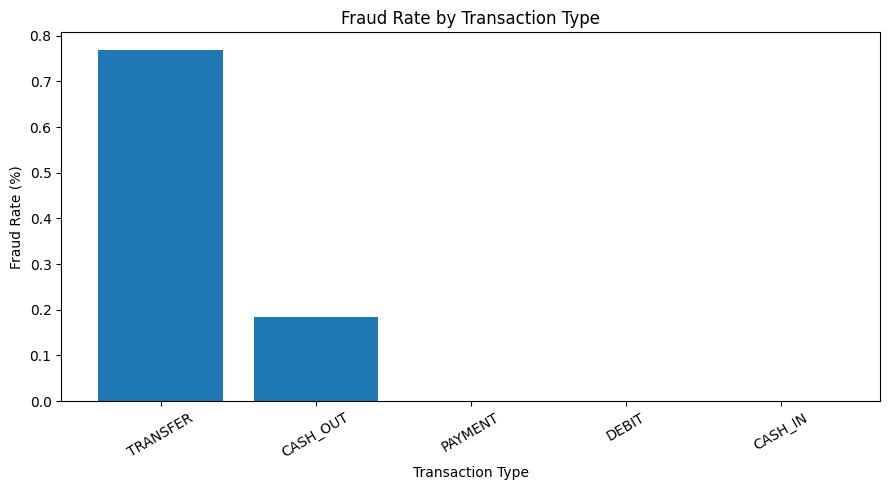

In [46]:
plt.figure(figsize=(9, 5))
plt.bar(
    fraud_by_type["type"],
    fraud_by_type["fraud_rate_percent"]
)
plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Transaction volume versus fraud count

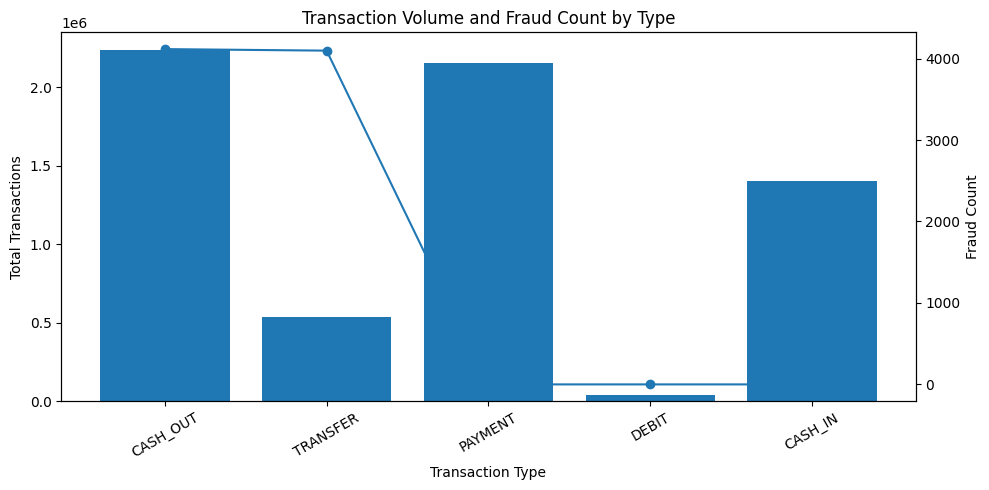

In [47]:
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(
    volume_analysis["type"],
    volume_analysis["transaction_count"]
)
ax1.set_xlabel("Transaction Type")
ax1.set_ylabel("Total Transactions")
ax1.tick_params(axis="x", rotation=30)

ax2 = ax1.twinx()
ax2.plot(
    volume_analysis["type"],
    volume_analysis["fraud_count"],
    marker="o"
)
ax2.set_ylabel("Fraud Count")

plt.title("Transaction Volume and Fraud Count by Type")
fig.tight_layout()
plt.show()

# Fraud Monitoring Rule

The initial scenario, flag a transaction if:
* Its type is TRANSFER or CASH_OUT; and
* Its amount is at least 200,000.

In [48]:
rule_query = """
SELECT
    COUNT(*) AS total_transactions,
    SUM(
        CASE
            WHEN type IN ('TRANSFER', 'CASH_OUT')
             AND amount >= 200000
            THEN 1 ELSE 0
        END
    ) AS flagged_transactions,
    SUM(
        CASE
            WHEN type IN ('TRANSFER', 'CASH_OUT')
             AND amount >= 200000
             AND isFraud = 1
            THEN 1 ELSE 0
        END
    ) AS fraud_flagged
FROM transactions;
"""

pd.read_sql_query(rule_query, conn)

,total_transactions,flagged_transactions,fraud_flagged
0,6362620,1197669,5471


In [49]:
# retrieving the data needed for evaluation; only 3 columns

evaluation_query = """
SELECT
    type,
    amount,
    isFraud
FROM transactions;
"""

evaluation_df = pd.read_sql_query(evaluation_query, conn)

evaluation_df.head()

,type,amount,isFraud
0,PAYMENT,9839.64,0
1,PAYMENT,1864.28,0
2,TRANSFER,181.00,1
3,CASH_OUT,181.00,1
4,PAYMENT,11668.14,0


Distinguishing four outcomes

| Outcome | Meaning |
|---|---|
|True positive (TP) | Fraud correctly flagged|
|False positive (FP)| Legitimate transaction incorrectly flagged |
|False negative (FN)| Fraud missed by the rule|
|True negative (TN) | Legitimate transaction correctly left unflagged|


In [50]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score

actual = evaluation_df["isFraud"].astype(int)

predicted = (
    evaluation_df["type"].isin(["TRANSFER", "CASH_OUT"])
    & (evaluation_df["amount"] >= 200000)
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    actual, predicted, labels=[0, 1]
).ravel()

precision = precision_score(
    actual, predicted, zero_division=0
)
recall = recall_score(
    actual, predicted, zero_division=0
)
false_positive_rate = fp / (fp + tn) if (fp + tn) else 0

metrics = pd.DataFrame({
    "Metric": [
        "True positives",
        "False positives",
        "False negatives",
        "True negatives",
        "Precision",
        "Recall",
        "False-positive rate",
        "Total transactions flagged"
    ],
    "Value": [
        tp, fp, fn, tn,
        round(precision, 4),
        round(recall, 4),
        round(false_positive_rate, 4),
        int(predicted.sum())
    ]
})

metrics

,Metric,Value
0,True positives,5.471000e+03
1,False positives,1.192198e+06
2,False negatives,2.742000e+03
3,True negatives,5.162209e+06
4,Precision,4.600000e-03
5,Recall,6.661000e-01
6,False-positive rate,1.876000e-01
7,Total transactions flagged,1.197669e+06


How to interpret these metrics
* Precision: Of the transactions flagged, what proportion were actually fraudulent? Higher precision generally means fewer wasted investigations.
* Recall: Of all fraudulent transactions, what proportion did the rule catch? Higher recall means fewer missed fraud cases.
* False-positive rate: Of all legitimate transactions, what proportion did the rule incorrectly flag?
* Alert volume: How many transactions would the team need to review?

In [51]:
# Compairing several thresholds

thresholds = [50000, 100000, 200000, 500000, 1000000]

results = []

eligible_type = evaluation_df["type"].isin(
    ["TRANSFER", "CASH_OUT"]
)

for threshold in thresholds:
    prediction = (
        eligible_type
        & (evaluation_df["amount"] >= threshold)
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, prediction, labels=[0, 1]
    ).ravel()

    results.append({
        "amount_threshold": threshold,
        "alerts": int(prediction.sum()),
        "true_positives": int(tp),
        "false_positives": int(fp),
        "missed_fraud": int(fn),
        "precision": precision_score(
            actual, prediction, zero_division=0
        ),
        "recall": recall_score(
            actual, prediction, zero_division=0
        ),
        "false_positive_rate": (
            fp / (fp + tn) if (fp + tn) else 0
        )
    })

threshold_results = pd.DataFrame(results)
threshold_results.round(4)

,amount_threshold,alerts,true_positives,false_positives,missed_fraud,precision,recall,false_positive_rate
0,50000,2359396,7175,2352221,1038,0.0030,0.8736,0.3702
1,100000,1934297,6506,1927791,1707,0.0034,0.7922,0.3034
2,200000,1197669,5471,1192198,2742,0.0046,0.6661,0.1876
3,500000,314301,3864,310437,4349,0.0123,0.4705,0.0489
4,1000000,130507,2706,127801,5507,0.0207,0.3295,0.0201


Visualization

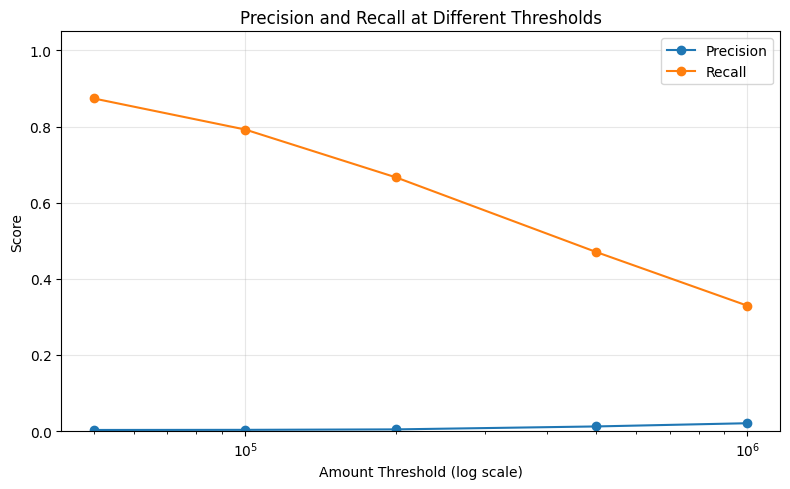

In [52]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_results["amount_threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_results["amount_threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)

plt.xscale("log")
plt.xlabel("Amount Threshold (log scale)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("Precision and Recall at Different Thresholds")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Key Findings

Analysis of the PaySim synthetic transaction dataset showed that observed fraud was concentrated in TRANSFER and CASH_OUT transactions. TRANSFER had the highest fraud rate at 0.7688%, while CASH_OUT accounted for the largest number of fraud cases, with 4,116 cases compared with 4,097 for TRANSFER.

A rule flagging TRANSFER and CASH_OUT transactions above a specified amount threshold demonstrated a clear trade-off between fraud detection and alert volume. At a threshold of 50,000, the rule achieved 87.36% recall but generated approximately 2.36 million alerts, with precision of just 0.30%. Increasing the threshold to 1,000,000 reduced alerts to 130,507 and improved precision to 2.07%, but recall declined to 32.95%.

These results suggest that amount-based rules can help narrow down suspicious activity, but they may generate too many false positives or miss a substantial proportion of fraud. Further analysis of transaction behaviour and account-level patterns is needed before recommending a monitoring rule for operational use.